In [1]:
# Instalación de la librería desde GitHub
%pip install git+https://github.com/05Pablo/practica.git

# Importaciones
import pandas as pd
import esperanto_nlp
from IPython.display import display

# Cargar el modelo de Esperanto
nlp = esperanto_nlp.load()

# Descargar el dataset desde GitHub
DATASET_URL = "https://raw.githubusercontent.com/05Pablo/practica/main/data/dataset.csv"
df = pd.read_csv(DATASET_URL, sep=";")

# Comprobar que se ha cargado correctamente
print("Dimensiones del dataset:", df.shape)
print("\nClases disponibles:", df["class"].unique())
display(df.head())

  Cloning https://github.com/05Pablo/practica.git to /tmp/pip-req-build-n88epldy
  Running command git clone --filter=blob:none --quiet https://github.com/05Pablo/practica.git /tmp/pip-req-build-n88epldy
  Resolved https://github.com/05Pablo/practica.git to commit 47e75c6c0527d4dcf77cfd599744ebd11ceb5efc
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for esperanto-nlp: filename=esperanto_nlp-0.2.0-py3-none-any.whl size=20656 sha256=398580fff5bbdfc4e7feca0d7a88a5ccadb5a3b2d33e86f419c99acfed3a1676
  Stored in directory: /tmp/pip-ephem-wheel-cache-ixakc_j9/wheels/7e/8e/ab/e1fd5921bfe6d4599ffe7ea4175e0cc0657f52b029d965db9f
Successfully built esperanto-nlp
Dimensiones del dataset: (4725, 2)

Clases disponibles: ['kristanismo' 'islamo' 'judismo']


,text,class
0,La parabolo de la edziĝa festo estas unu el la...,kristanismo
1,Luko: “16 Sed li diris: “Unu viro faris granda...,kristanismo
2,"Mateo: “1 Kaj respondante, Jesuo denove paroli...",kristanismo
3,Tomaso:. Jesuo diris: “Homo aranĝis ricevon. K...,kristanismo
4,"En Paralelaj pasaĵoj, Mateo (22,1-14) lokigas ...",kristanismo


Número de párrafos por clase:


,Número de párrafos
class,
kristanismo,2243
judismo,1397
islamo,1085


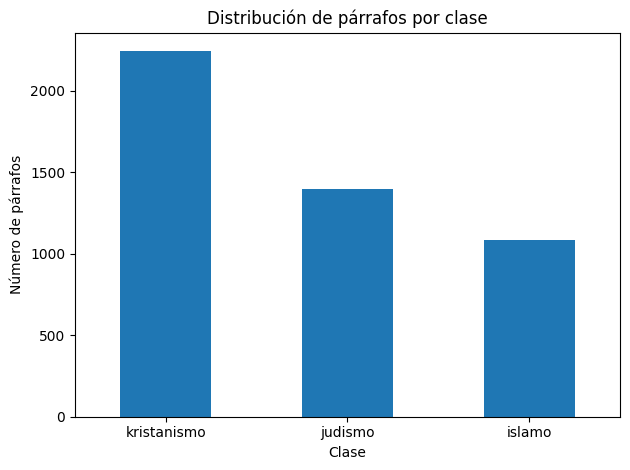

In [2]:

import matplotlib.pyplot as plt

# Número de párrafos por clase
conteo_clases = df["class"].value_counts()

print("Número de párrafos por clase:")
display(conteo_clases.to_frame(name="Número de párrafos"))

# Gráfico de distribución
conteo_clases.plot(kind="bar", rot=0)
plt.title("Distribución de párrafos por clase")
plt.xlabel("Clase")
plt.ylabel("Número de párrafos")
plt.tight_layout()
plt.show()


Estadísticas de longitud de los párrafos:


,longitud
count,4725.000000
mean,59.081905
std,41.132948
min,15.000000
25%,29.000000
50%,48.000000
75%,76.000000
max,364.000000


Longitud media por clase:


,Longitud media
class,
islamo,66.349309
judismo,56.265569
kristanismo,57.320553


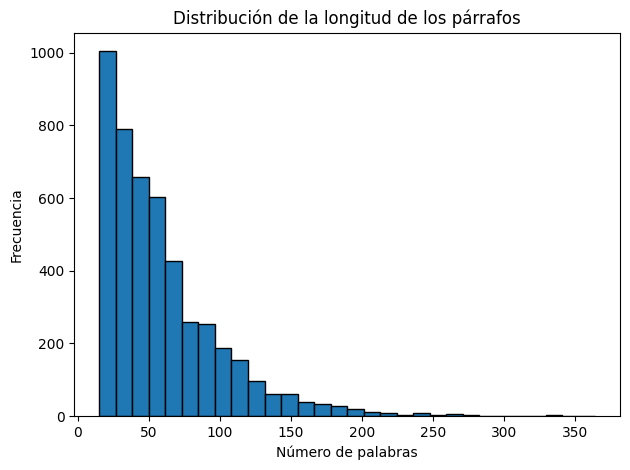

In [3]:

# Calcular la longitud de cada párrafo en palabras
df["longitud"] = df["text"].astype(str).apply(lambda texto: len(texto.split()))

# Estadísticas generales
print("Estadísticas de longitud de los párrafos:")
display(df["longitud"].describe().to_frame())

# Longitud media por clase
print("Longitud media por clase:")
display(df.groupby("class")["longitud"].mean().to_frame("Longitud media"))

# Distribución de las longitudes
df["longitud"].plot(kind="hist", bins=30, edgecolor="black")
plt.title("Distribución de la longitud de los párrafos")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()


## 3. Preprocesado con nuestra librería

Usamos `esperanto_nlp` para tokenizar y lematizar. Nos quedamos con los **lemas en minúsculas** de las palabras alfabéticas (`is_alpha`) que **no** son stop-words (`is_stop`). Así `judoj`, `judon` y `judo` acaban siendo el mismo término, y se eliminan puntuación, números y palabras funcionales (`la`, `kaj`, `en`...).

In [4]:
import random
import numpy as np

# Semillas fijas para que los resultados sean reproducibles
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Las clases salen del dataset (nada escrito a mano), así que el cuaderno
# funciona con el dataset de otro equipo cambiando solo DATASET_URL
CLASSES = sorted(df["class"].unique())
print("Clases:", CLASSES)


def preprocess(text):
    """Lemas en minúsculas de las palabras alfabéticas que no son stop-words."""
    return [t.lemma_.lower() for t in nlp(text) if t.is_alpha and not t.is_stop]


# Ejemplo antes / después
ejemplo = df["text"].iloc[0]
lemas = preprocess(ejemplo)
print("Texto original   :", ejemplo[:200], "...")
print("Tras preprocesar :", lemas[:15], "...")
print(f"Tokens: {len(ejemplo.split())} palabras -> {len(lemas)} lemas útiles")

Clases: ['islamo', 'judismo', 'kristanismo']
Texto original   : La parabolo de la edziĝa festo estas unu el la paraboloj de Jesuo rakontita en la evangelio laŭ Mateo (22,1-14), en tiu de Luko kaj en la apokrifa La evangelio de Tomaso([1]). ...
Tras preprocesar : ['parabolo', 'edziĝa', 'festo', 'parabolo', 'jesuo', 'rakontita', 'evangelio', 'mateo', 'luko', 'apokrifa', 'evangelio', 'tomaso'] ...
Tokens: 32 palabras -> 12 lemas útiles


## 4. Representación TF-IDF

`TfidfVectorizer` acepta un `analyzer` propio: le pasamos `preprocess`, de modo que el vocabulario se construye con los lemas de **nuestra** librería y no con el tokenizador por defecto de scikit-learn. TF-IDF da más peso a los términos frecuentes en un párrafo pero poco comunes en el resto del corpus.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer


def make_tfidf():
    return TfidfVectorizer(analyzer=preprocess)


# Demostración sobre una muestra pequeña
demo = make_tfidf()
matriz = demo.fit_transform(df["text"].head(200))
print("Matriz TF-IDF (200 párrafos):", matriz.shape,
      "-> documentos x términos del vocabulario")

Matriz TF-IDF (200 párrafos): (200, 3249) -> documentos x términos del vocabulario


## 5. Entrenamiento y comparación de modelos

Separamos **train (80 %) y test (20 %)** de forma estratificada y con `random_state=42`, para mantener la proporción de clases y poder reproducir el resultado. Cada modelo es un `Pipeline` (TF-IDF + clasificador), de modo que el TF-IDF se ajusta **solo con el train** y no hay fuga de información hacia el test.

Comparamos:
- **Naive Bayes multinomial**: línea base clásica para texto.
- **Complement Naive Bayes**: variante de Naive Bayes pensada para clases desequilibradas.
- **Regresión logística** con `class_weight="balanced"`: pondera más las clases minoritarias por el desequilibrio (kristanismo tiene el doble de párrafos que islamo).

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["class"],
    test_size=0.2, stratify=df["class"], random_state=SEED,
)
print("Train:", len(X_train), "| Test:", len(X_test))

modelos = {
    "Naive Bayes": Pipeline([("tfidf", make_tfidf()), ("clf", MultinomialNB())]),
    "Complement NB": Pipeline([("tfidf", make_tfidf()), ("clf", ComplementNB())]),
    "Regresión logística": Pipeline([
        ("tfidf", make_tfidf()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000,
                                   random_state=SEED)),
    ]),
}

predicciones, filas = {}, []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    predicciones[nombre] = pred
    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "F1 macro": f1_score(y_test, pred, average="macro"),
    })

comparativa = pd.DataFrame(filas).set_index("Modelo").round(3)
display(comparativa)

Train: 3780 | Test: 945


,Accuracy,F1 macro
Modelo,,
Naive Bayes,0.798,0.781
Complement NB,0.887,0.884
Regresión logística,0.895,0.892


## 6. Evaluación

Como las clases están desequilibradas, la métrica de referencia es el **F1 macro** (promedia el F1 de cada clase sin dar más peso a la mayoritaria); la *accuracy* por sí sola podría ocultar que se ignoran las clases pequeñas.

Mejor modelo según F1 macro: Regresión logística

              precision    recall  f1-score   support

      islamo      0.926     0.871     0.898       217
     judismo      0.864     0.867     0.866       279
 kristanismo      0.900     0.924     0.912       449

    accuracy                          0.895       945
   macro avg      0.897     0.888     0.892       945
weighted avg      0.896     0.895     0.895       945



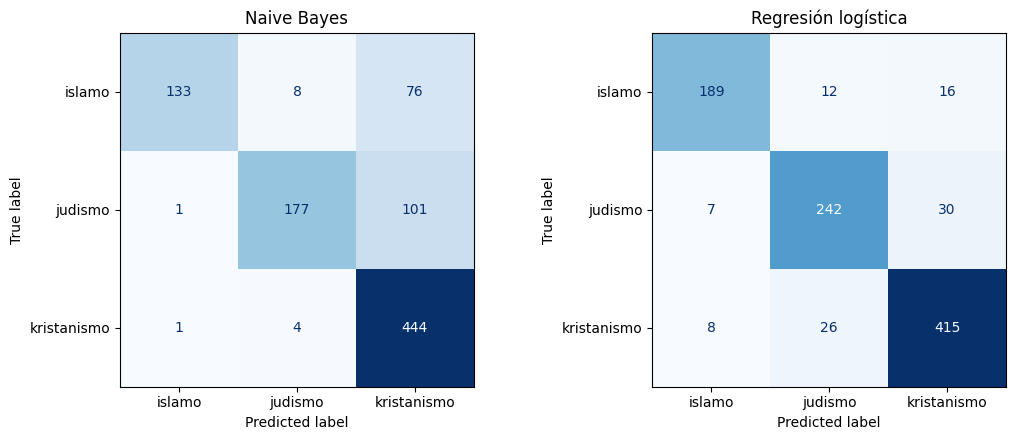

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

mejor = comparativa["F1 macro"].idxmax()
print("Mejor modelo según F1 macro:", mejor)
print()
print(classification_report(y_test, predicciones[mejor], digits=3))

# Matriz de confusión: línea base (Naive Bayes) frente al mejor modelo
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for eje, nombre in zip(ejes, ["Naive Bayes", mejor]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicciones[nombre], labels=CLASSES,
        cmap="Blues", ax=eje, colorbar=False,
    )
    eje.set_title(nombre)
plt.tight_layout()
plt.show()

### Análisis de errores

Para entender **qué clases se confunden y por qué** miramos los términos con más peso en la regresión logística y algunos párrafos mal clasificados.

In [8]:
modelo_lr = modelos["Regresión logística"]
terminos = modelo_lr.named_steps["tfidf"].get_feature_names_out()
coefs = modelo_lr.named_steps["clf"].coef_
clases_lr = modelo_lr.named_steps["clf"].classes_

print("Términos más característicos de cada clase (mayor peso):\n")
for i, clase in enumerate(clases_lr):
    top = terminos[np.argsort(coefs[i])[-12:][::-1]]
    print(f"{clase:12s}", ", ".join(top))

# Párrafos mal clasificados por la regresión logística
pred_lr = predicciones["Regresión logística"]
errores = pd.DataFrame({"texto": X_test.values, "real": y_test.values, "predicho": pred_lr})
errores = errores[errores["real"] != errores["predicho"]]
print(f"\nErrores: {len(errores)} de {len(y_test)} párrafos de test")
print("\nErrores más frecuentes (real -> predicho):")
display(errores.groupby(["real", "predicho"]).size().sort_values(ascending=False).to_frame("n"))

print("\nEjemplos de párrafos mal clasificados:")
for _, fila in errores.sample(4, random_state=SEED).iterrows():
    print(f"[{fila['real']} -> {fila['predicho']}] {fila['texto'][:230]}...\n")

Términos más característicos de cada clase (mayor peso):

islamo       islama, islamo, korano, islamano, araba, arabe, kalifo, sklavo, moskeo, sklaveco, umar, mekko
judismo      juda, judo, einstein, israelo, judismo, esperanto, hebree, hebrea, zamenhof, popolo, naskiĝi, usono
kristanismo  eklezio, kristana, sankta, jesuo, episkopo, greka, apostolo, kristano, aramea, kristanismo, kristo, teologio

Errores: 99 de 945 párrafos de test

Errores más frecuentes (real -> predicho):


n
real        predicho       
judismo     kristanismo  30
kristanismo judismo      26
islamo      kristanismo  16
            judismo      12
kristanismo islamo        8
judismo     islamo        7


Ejemplos de párrafos mal clasificados:
[islamo -> kristanismo] La verkon oni adresas per dua persono al la plej proksima amikino, kies nomon oni ne diras /same kiel apenaŭ tiu de la rakontistino), kontraste kun ĉiuj aliaj nomitaj roluloj....

[judismo -> kristanismo] Свободная эмиграция из СССР подготовлена в Кливленде (Libera elmigrado el Sovet-Unio estis preparita en Cleveland.)...

[judismo -> kristanismo] La objekto estis konstruita el brikoj en la 2-a duono de la 19-a jarcento. Ĝi estas duetaĝa domo kun duonrondaj fenestroj. Ĉe ĝia okcidenta flanko troviĝas alkonstruita kromdomo. La sinagogo estis parte bruligita fine de la 19-a j...

[judismo -> kristanismo] Im Dienste der Wahrheit genügt es nicht, Geist zu zeigen, man muß auch Mut zeigen (Servante la veron ne sufiĉas montri spritecon sed necesas ankaŭ kuraĝo.)...



**Qué se confunde y por qué**

- **Naive Bayes (línea base) está sesgado hacia la clase mayoritaria.** Casi todo lo dudoso lo manda a `kristanismo` (recall ≈ 0,99 pero precisión ≈ 0,72), y islamo y judismo pierden recall (≈ 0,61 y 0,63). Con `ComplementNB` o con la regresión logística y `class_weight="balanced"` el comportamiento se reequilibra y el F1 macro sube de ≈ 0,78 a ≈ 0,89. El problema era el desequilibrio de clases más que el algoritmo.
- **Judismo ↔ cristianismo es la confusión principal** (unos 30 y 26 párrafos en cada sentido). Las dos tradiciones comparten vocabulario y personajes bíblicos (Biblia, libros del Antiguo Testamento, relatos de Babilonia, Ĥanoĥ...), así que el contenido es genuinamente ambiguo y un modelo basado en palabras no puede separarlo bien.
- **Ruido de etiquetas en el dataset.** La clase se asigna por la categoría de Vikipedio del artículo, no por el contenido de cada párrafo. En `judismo` caen biografías de personas judías (en los términos más pesados aparecen `einstein`, `zamenhof`, `esperanto`, `usono`) y citas en ruso o alemán sin vocabulario religioso, y el modelo las manda a otra clase. Parte de esos errores no son del modelo sino de la etiqueta.
- **Párrafos sin señal religiosa** (descripciones de un edificio, un comentario literario) se clasifican casi al azar, con la prior de la clase más frecuente.

Los términos de mayor peso por clase (`korano`, `moskeo` / `eklezio`, `jesuo` / `juda`, `hebrea`) son coherentes con cada tema, lo que indica que el modelo aprende vocabulario temático y no artefactos.

## 7. Clasificación de páginas web en Esperanto

Descargamos páginas de Vikipedio sobre religión, extraemos el texto de los párrafos con `requests` + `BeautifulSoup` y los clasificamos con la regresión logística. Como el modelo se entrenó con **párrafos**, clasificamos cada párrafo de la página y **promediamos** las probabilidades (`predict_proba`).

Elegimos artículos que **no están en el dataset** (comprobado en `sources.csv`) para que sea una prueba real, una por clase. La clase esperada solo se usa para comparar, nunca para clasificar.

Si una descarga falla (sin conexión, timeout, error HTTP), el cuaderno **no se rompe**: muestra un aviso y continúa con la siguiente página.

https://eo.wikipedia.org/wiki/Ramadano
  4 párrafos | esperada: islamo | predicha: islamo
  islamo: 58.1% | judismo: 21.5% | kristanismo: 20.4%

No se pudo clasificar https://eo.wikipedia.org/wiki/Hanuko: HTTPError: 404 Client Error: Not Found for url: https://eo.wikipedia.org/wiki/Hanuko
https://eo.wikipedia.org/wiki/Kristnasko
  11 párrafos | esperada: kristanismo | predicha: kristanismo
  islamo: 18.7% | judismo: 29.9% | kristanismo: 51.4%



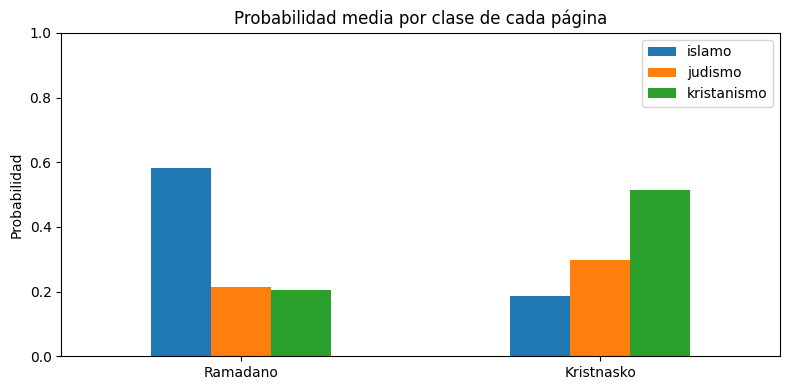

No se pudo clasificar https://esta-pagina-no-existe.invalid/: ConnectionError: HTTPSConnectionPool(host='esta-pagina-no-existe.invalid', port=443): Max retries exceeded with url: / (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x7fa5c40d9950>: Failed to resolve 'esta-pagina-no-existe.invalid' ([Errno -2] Name or service not known)"))


In [9]:
import re
import requests
from bs4 import BeautifulSoup

HEADERS = {"User-Agent": "Mozilla/5.0 (cuaderno clasificador de textos en Esperanto)"}
TIMEOUT = 10  # segundos

# (URL, clase esperada solo para comparar). Artículos que no están en el dataset.
PAGINAS = [
    ("https://eo.wikipedia.org/wiki/Ramadano", "islamo"),
    ("https://eo.wikipedia.org/wiki/Hanuko", "judismo"),
    ("https://eo.wikipedia.org/wiki/Kristnasko", "kristanismo"),
]


def extraer_parrafos(html, min_palabras=15):
    """Devuelve los párrafos de texto de una página (sin referencias ni tablas)."""
    soup = BeautifulSoup(html, "html.parser")
    for etiqueta in soup(["script", "style", "sup", "table"]):
        etiqueta.decompose()
    contenedor = soup.select_one("div.mw-parser-output") or soup
    parrafos = [re.sub(r"\s+", " ", p.get_text(" ", strip=True))
                for p in contenedor.find_all("p")]
    return [p for p in parrafos if len(p.split()) >= min_palabras]


def clasificar_web(url, modelo):
    """Probabilidad media por clase de una página, o None si algo falla."""
    try:
        respuesta = requests.get(url, headers=HEADERS, timeout=TIMEOUT)
        respuesta.raise_for_status()
        parrafos = extraer_parrafos(respuesta.text)
        if not parrafos:
            print(f"Sin texto aprovechable en {url}")
            return None
        probs = modelo.predict_proba(parrafos).mean(axis=0)
        return pd.Series(probs, index=modelo.classes_), len(parrafos)
    except Exception as e:  # red, timeout, HTTP, HTML inesperado...
        print(f"No se pudo clasificar {url}: {type(e).__name__}: {e}")
        return None


resultados_web = {}
for url, esperada in PAGINAS:
    salida = clasificar_web(url, modelo_lr)
    if salida is None:
        continue
    probs, n = salida
    resultados_web[url.rsplit("/", 1)[-1]] = probs
    print(f"{url}\n  {n} párrafos | esperada: {esperada} | predicha: {probs.idxmax()}")
    print("  " + " | ".join(f"{c}: {p:.1%}" for c, p in probs.items()) + "\n")

if resultados_web:
    pd.DataFrame(resultados_web).T.plot(kind="bar", rot=0, figsize=(8, 4))
    plt.title("Probabilidad media por clase de cada página")
    plt.ylabel("Probabilidad")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()
else:
    print("No se pudo clasificar ninguna página; revisa la conexión y vuelve a ejecutar.")

# Comprobación de robustez: una URL que falla no rompe el cuaderno
clasificar_web("https://esta-pagina-no-existe.invalid/", modelo_lr)

**Cómo interpretar el resultado**

- La probabilidad de cada página es la **media de las probabilidades de sus párrafos**. Una página claramente temática debería concentrar la mayor parte en una clase, pero nunca llegará al 100 %: hay párrafos introductorios, históricos o de contexto con poco vocabulario específico.
- Lo esperable es que las páginas de fiestas o conceptos de una sola tradición se clasifiquen bien, y que si hay duda sea entre `judismo` y `kristanismo`, por lo visto en el análisis de errores.
- **Limitaciones:** el modelo solo conoce tres religiones, así que una página sobre otra religión o un tema ajeno se asignará igualmente a la clase "menos mala". Además, el estilo de Vikipedio coincide con el del dataset, por lo que en otras fuentes (blogs, noticias) el rendimiento podría ser menor.

**Resultado obtenido:**